In [2]:
%pip install pandas
%pip install matplotlib
%pip install numpy
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np


[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.

[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.

[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


        x   y    z     timestamp
0      28 -88  232  3.443750e+05
1      24 -88  230  3.445345e+05
2      24 -86  228  3.446940e+05
3      24 -88  226  3.448535e+05
4      24 -88  230  3.450130e+05
...    ..  ..  ...           ...
92395 -46 -48  212  3.254858e+07
92396 -38 -54  216  3.254886e+07
92397 -48 -40  214  3.254915e+07
92398 -46 -52  210  3.254943e+07
92399 -44 -46  210  3.254972e+07

[92400 rows x 4 columns]


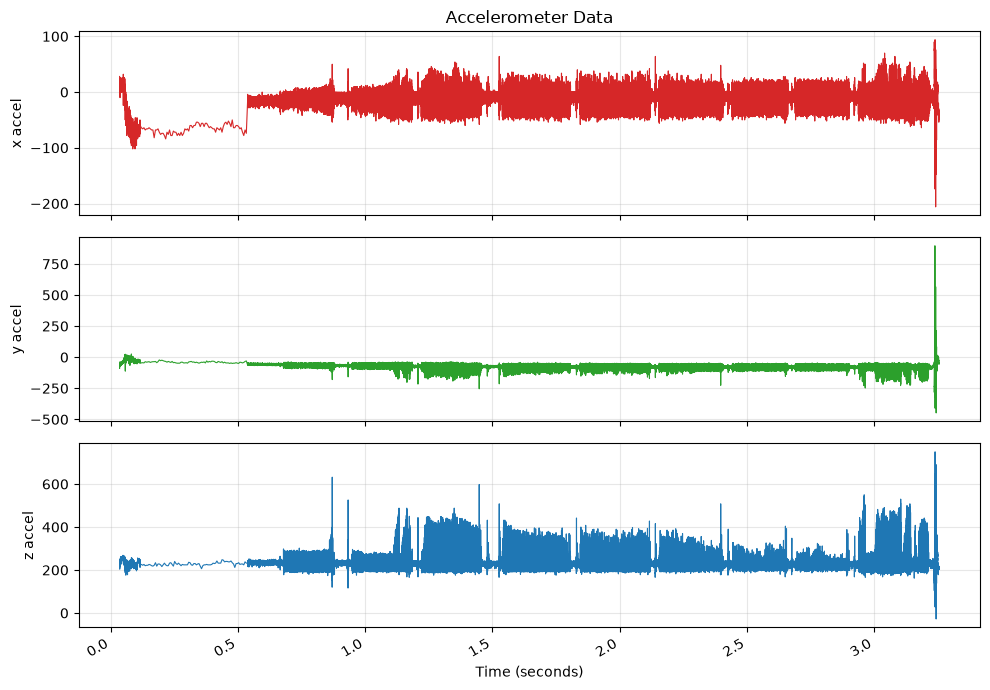

In [18]:
# Load data
df = pd.read_csv("log_10_24_6.csv")

block_t = df.groupby("block_seq")["t_us"].first() # One start time per block
block_dt = block_t.shift(-1) - block_t # Duration of each block
block_dt = block_dt.fillna(block_dt.iloc[-2])
df["t_us_diff"] = df["block_seq"].map(block_dt) # Attach each block's duration to its rows

df["timestamp"] = df["t_us"] + df["sample_index_in_block"] * df["t_us_diff"] / 84

df2 = df.drop(columns=["block_seq", "sample_index_in_block", "t_us_diff", "t_us"])
print(df2)

# Plot all three axes
fig, axes = plt.subplots(3, 1, figsize=(10, 7), sharex=True)

for ax, col, color in zip(axes, ["x", "y", "z"], ["tab:red", "tab:green", "tab:blue"]):
    ax.plot(df["timestamp"] / (10e6), df[col], color=color, linewidth=0.8)
    ax.set_ylabel(f"{col} accel")
    #ax.set_ylim(-256, 256)
    #ax.set_xlim(1, 2)
    ax.grid(True, alpha=0.3)

axes[0].set_title("Accelerometer Data")
axes[-1].set_xlabel("Time (seconds)")

fig.autofmt_xdate()
plt.tight_layout()
plt.show()

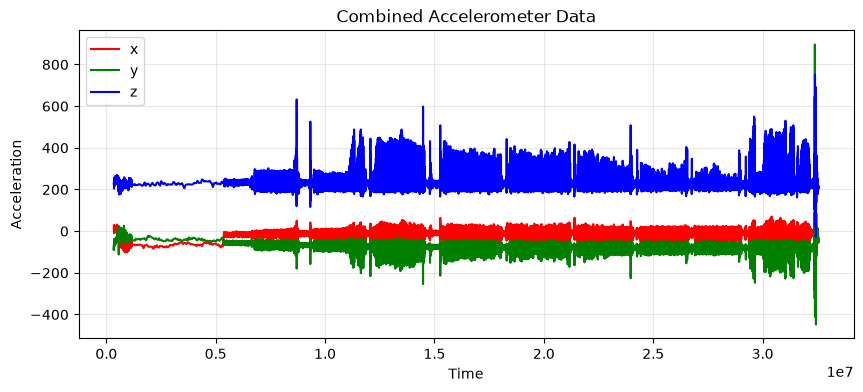

In [15]:
plt.figure(figsize=(10, 4))
plt.plot(df["timestamp"], df["x"], label="x", c="red")
plt.plot(df["timestamp"], df["y"], label="y", c="green")
plt.plot(df["timestamp"], df["z"], label="z", c="blue")
plt.xlabel("Time")
plt.ylabel("Acceleration")
plt.title("Combined Accelerometer Data")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()